# Estimando o desempenho de classificadores - Mineração de Dados
Alunos:
- Matheus Peixoto Ribeiro Vieira - 22.1.4104
- Pedro Henrique Rabelo Leão de Oliveira - 22.1.4022

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Só usamos o 'train.csv', pois o 'test.csv' fornecido pelo site não tem a coluna da label
df = pd.read_csv('train.csv')
df
# Para classificação de atributos eu desconsidero o survived porque ele é a label e não um atributo

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Preparando os dados para os modelos

**Classificando os atributos**:

PassengerId - Discreto (já que ele assume valores inteiros e contáveis)

Pclass - Categórico Ordinal (já que representa uma categoria com ordem natural)

Name - Categórico Nominal (já que representa uma categoria sem ordem)

Sex - Binário Assimétrico (já que é um atributo de apenas dois valores e ambos não tem a mesma importância, logo, se houvesse uma troca entre os valores alteraria a análise)

Age - Contínuo (já que ele pode assumir qualquer valor dentro de um intervalo)

SibSp - Discreto (já que ele assume valores inteiros e contáveis)

Parch - Discreto (já que ele assume valores inteiros e contáveis)

Ticket - Categórico Nominal (já que representa uma categoria sem ordem)

Fare - Contínuo (já que ele pode assumir qualquer valor dentro de um intervalo)

Cabin - Categórico Nominal (já que representa uma categoria sem ordem)

Embarked - Categórico Nominal (já que representa uma categoria sem ordem)

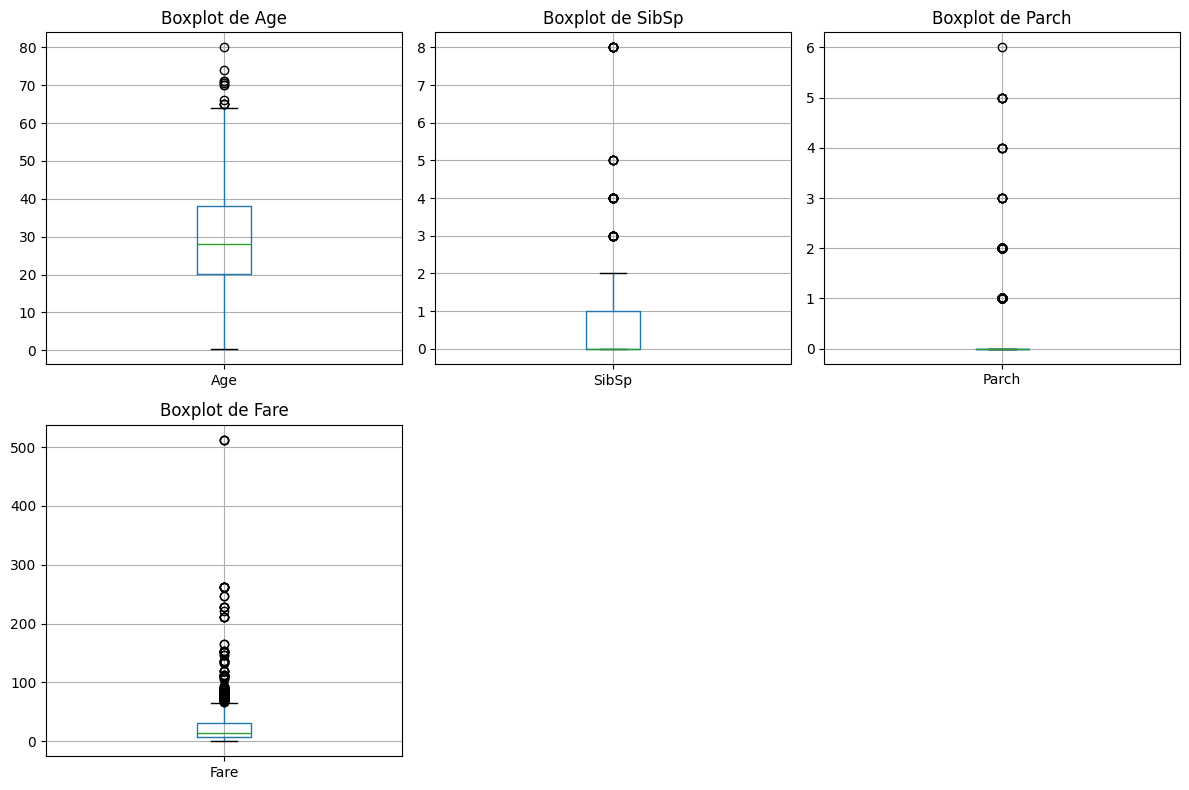

In [ ]:
atributosNumericos = ['Age', 'SibSp', 'Parch', 'Fare']

plt.figure(figsize=(12, 8))
for i, atributo in enumerate(atributosNumericos):
    plt.subplot(2, 3, i+1)
    df.boxplot(column=atributo)
    plt.title(f'Boxplot de {atributo}')
plt.tight_layout()
plt.show()

In [ ]:
# Suavizando ruídos
for atributo in atributosNumericos:
  Q1 = df[atributo].quantile(0.25)
  Q3 = df[atributo].quantile(0.75)
  AIQ = Q3 - Q1
  upper_bound = Q3 + 1.5 * AIQ

  bounds, _ = pd.cut(df[atributo], 4, retbins=True)

  for index, row in df.iterrows():
      if row[atributo] > upper_bound:
          mean = (bounds[index].left + bounds[index].right) / 2.0
          df.loc[index, atributo] = mean

/tmp/ipython-input-3461047455.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.747' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[index, atributo] = mean


In [ ]:
# Dropando os atributos 'PassengerId', 'Name' e 'Ticket' uma vez que eles não tem valor para a classificação
# de sobrevivente, eles são apenas uma forma de identificar um passageiro único
df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)

In [ ]:
# Lidando com valores nulos
def check_null_itens(df):
    for index, value in df.isnull().any().items():
        if value:
            print(f"{index} contains {df[index].isnull().sum()} null values")

check_null_itens(df)

Age contains 177 null values
Cabin contains 687 null values
Embarked contains 2 null values


In [ ]:
# Preenchendo valores ausentes
mean_age = df['Age'].mean()
df['Age'] = df['Age'].fillna(mean_age)

# U = Unknown
df['Cabin'] = df['Cabin'].fillna('U')
# O número da cabine é formado por uma letra seguida de um número, portanto, se eu pegar
# essa letra inicial, pode me trazer uma informação interessante da localização do passageiro no navio
df['Cabin'] = df['Cabin'].astype(str).str[0]

mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(mode)

In [ ]:
# Aplicando one-hot encoded em atributos categóricos nominais e sex (que é como se fosse um também)
cols_to_encode = ['Sex', 'Embarked', 'Cabin']
df = pd.get_dummies(df, columns=cols_to_encode, prefix=cols_to_encode)

df['Pclass'] = df['Pclass'].astype(int)

# Normalizando atributos numéricos
for atributo in atributosNumericos+['Pclass']:
  min = df[atributo].min()
  max = df[atributo].max()
  df[atributo] = (df[atributo] - min) / (max - min)

In [ ]:
df

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_T,Cabin_U
0,0,1.0,0.309913,0.142857,0.000000,0.016173,False,True,False,False,True,False,False,False,False,False,False,False,False,True
1,1,0.0,0.539691,0.142857,0.000000,0.142286,True,False,True,False,False,False,False,True,False,False,False,False,False,False
2,1,1.0,0.367357,0.000000,0.000000,0.017678,True,False,False,False,True,False,False,False,False,False,False,False,False,True
3,1,0.0,0.496607,0.142857,0.000000,0.118451,True,False,False,False,True,False,False,True,False,False,False,False,False,False
4,0,1.0,0.496607,0.000000,0.000000,0.017957,False,True,False,False,True,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,0.5,0.381718,0.000000,0.000000,0.028999,False,True,False,False,True,False,False,False,False,False,False,False,False,True
887,1,0.0,0.266829,0.000000,0.000000,0.066921,True,False,False,False,True,False,True,False,False,False,False,False,False,False
888,0,1.0,0.420543,0.142857,0.428571,0.052310,True,False,False,False,True,False,False,False,False,False,False,False,False,True
889,1,0.0,0.367357,0.000000,0.000000,0.066921,False,True,True,False,False,False,False,True,False,False,False,False,False,False


## Implementando os classificadores

### Árvore de Decisão

In [ ]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Separando os dados em treino e teste
x = df.drop('Survived', axis=1)
y = df['Survived']

In [ ]:
decision_tree = DecisionTreeClassifier()

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [4, 5, 6, 7, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=decision_tree,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',
    verbose=1
)

grid_search.fit(x, y)

Fitting 10 folds for each of 90 candidates, totalling 900 fits


GridSearchCV(cv=10, estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [4, 5, 6, 7, None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy', verbose=1)

In [ ]:
print(grid_search.best_params_)
print(grid_search.best_score_) # Melhor acurácia da cv

{'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 2}
0.8160049937578029


In [ ]:
scores_tree = cross_val_score(grid_search.best_estimator_, x, y, cv=10, scoring='accuracy')
print(f'Acurácia média: {scores_tree.mean():.4f}')
print(f'Desvio padrão: {scores_tree.std():.4f}')


Acurácia média: 0.8149
Desvio padrão: 0.0414


### Redes Neurais Artificias

In [ ]:
from sklearn.neural_network import MLPClassifier

In [ ]:
mlp = MLPClassifier()

param_grid = {
    'hidden_layer_sizes': [(16, 32, 16,), (32, 16,), (16, 32,)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'learning_rate_init': [0.001, 0.01],
    'batch_size': [32, 64],
    'max_iter': [500],
}

grid_search_mlp = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    cv=10,
    scoring='accuracy',
    verbose=1
)

grid_search_mlp.fit(x, y)

Fitting 10 folds for each of 48 candidates, totalling 480 fits


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptro

GridSearchCV(cv=10, estimator=MLPClassifier(),
             param_grid={'activation': ['relu', 'tanh'], 'batch_size': [32, 64],
                         'hidden_layer_sizes': [(16, 32, 16), (32, 16),
                                                (16, 32)],
                         'learning_rate_init': [0.001, 0.01], 'max_iter': [500],
                         'solver': ['adam', 'sgd']},
             scoring='accuracy', verbose=1)

In [ ]:
print(grid_search_mlp.best_params_)
print(grid_search_mlp.best_score_) # Melhor acurácia da cv

{'activation': 'relu', 'batch_size': 64, 'hidden_layer_sizes': (32, 16), 'learning_rate_init': 0.01, 'max_iter': 500, 'solver': 'sgd'}
0.8272034956304619


In [ ]:
scores_mlp = cross_val_score(grid_search_mlp.best_estimator_, x, y, cv=10, scoring='accuracy')
print(f'Acurácia média: {scores_mlp.mean():.4f}')
print(f'Desvio padrão: {scores_mlp.std():.4f}')

Acurácia média: 0.8317
Desvio padrão: 0.0359


### Análises dos resultados dos modelos e comparação entre eles

Escolhemos Árvore de Decisão e Redes Neurais Artificiais como nossas técnicas de indução de classificadores.

&nbsp;
#### Árvore de Decisão:
Foram executados 90 combinações de modelos para o gridSearch com uma validação cruzada de 10-fold, totalizando 900 treinamentos. Foram feitas variações dos parâmetros 'criterion', 'max_depth', 'min_samples_split' e 'min_samples_leaf'.

Ao final os melhores parâmetros obtidos entre os testados foram:
- criterion: gini
- max_depth: 7
- min_samples_leaf: 2
- min_samples_split: 2

Com eles, o melhor modelo obteve uma acurácia média de 0.8149 com desvio padrão de 0.0414.

Portanto, além da boa acurácia, o modelo de árvore de decisão mostrou uma variabilidade pequena nos folds, com um baixo desvio padrão, o que indica certa estabilidade, embora o desvio ainda permita alguma margem de variação nos resultados.

&nbsp;
#### Redes Neurais Artificiais
Foram executados 48 combinações de modelos para o gridSearch com uma validação cruzada de 10-fold, totalizando 480 treinamentos. Entretanto, mesmo assim, essa execução levou um tempo consideravelmente maior que a execução das árvores de decisão, uma vez que as redes neurais tem uma complexidade maior e, consequentemente, custos computacional e de tempo maiores. Durante o gridSearch, foram feitas variações dos parâmetros 'hidden_layer_sizes' (número e tamanho das camadas ocultas), 'activation', 'solver', 'learning_rate_init', 'batch_size' e 'max_iter'.

Ao final os melhores parâmetros obtidos entre os testados foram:
- activation: relu
- batch_size: 64
- hidden_layer_sizes: (32, 16)
- learning_rate_init: 0.01
- max_iter: 500
- solver: sgd

Com eles, o melhor modelo obteve uma acurácia média de 0.8317 com desvio padrão de 0.0359.

&nbsp;
#### Comparação entre os dois
Podemos observar que, as redes neurais obtiveram uma acurácia média maior que a árvore de decisão com um desvio padrão menor, portanto o resultado das redes neurais foi melhor para essa tarefa de classificação. Entretanto, se formos considerar do ponto de vista do custo computacional e de tempo, principalmente em problemas com escalas maiores, talvez a diferença de 0,0168 na acurácia não compense, já que é uma diferença muito pequena para custos muito maiores, além da árvore ser um modelo muito mais fácil de se interpretar uma classificação. Portanto, nesse caso, o trade-off entre acurácia e custos pode não valher a pena.